In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from pathlib import Path
import pandas as pd

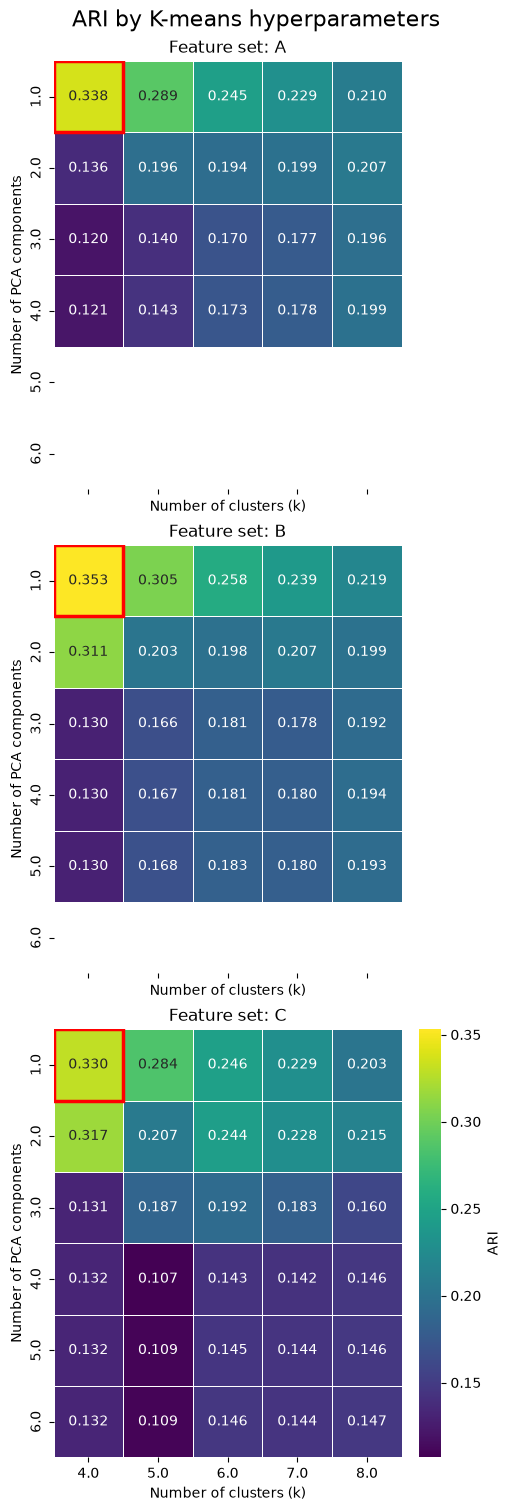

In [25]:
metrics = [
        "k",
        "inertia",
        "silhouette",
        "ARI",
        "NMI",
        "accuracy",
        "macro_F1",
        "n_classes_predicted",
        "val_error",
        "n_pca"
]
numeric_cols = [
    "k",
    "inertia",
    "silhouette",
    "ARI",
    "NMI",
    "accuracy",
    "macro_F1",
    "val_error",
    "n_classes_predicted",
    "n_pca"
]


kmeans_cluster_max = 8
kmeans_cluster_candidates = range(4, kmeans_cluster_max + 1)

optimize_metric = "ARI"  # ARI, silhouette, NMI, accuracy, macro_F1

# Metrics where a larger value is better
higher_is_better_metrics = {
    "ARI",
    "silhouette",
    "NMI",
    "accuracy",
    "macro_F1"
}

labels = ["A", "B", "C"]

# Use one common colour scale across every feature set,
# so the heatmaps are directly comparable.
all_scores = []

for label in labels:
    metrics_df = np.load(
        Path.cwd().parent / "saves" / "kmeans" / f"label_{label}_PCA.npy",
        allow_pickle=True
    )
    metrics_df = pd.DataFrame(metrics_df, columns=metrics)

    for col in numeric_cols:
        metrics_df[col] = pd.to_numeric(metrics_df[col], errors="coerce")

    all_scores.extend(metrics_df[optimize_metric].dropna().to_numpy())

vmin = min(all_scores)
vmax = max(all_scores)

# Higher ARI is better, so use a normal sequential colormap.
cmap = "viridis" if optimize_metric in higher_is_better_metrics else "viridis_r"

fig, axes = plt.subplots(
    len(labels), 1,
    figsize=(5, 5 * len(labels)),
    sharey=True,
    sharex=True,
    layout="constrained"
)

for j, label in enumerate(labels):
    metrics_df = np.load(
        Path.cwd().parent / "saves" / "kmeans" / f"label_{label}_PCA.npy",
        allow_pickle=True
    )
    metrics_df = pd.DataFrame(metrics_df, columns=metrics)

    numeric_cols = [
        "k",
        "inertia",
        "silhouette",
        "ARI",
        "NMI",
        "accuracy",
        "macro_F1",
        "n_classes_predicted",
        "val_error",
        "n_pca"
    ]

    for col in numeric_cols:
        metrics_df[col] = pd.to_numeric(metrics_df[col], errors="coerce")

    ax = np.atleast_1d(axes)[j]

    pivot = (
        metrics_df
        .pivot(
            index="n_pca",
            columns="k",
            values=optimize_metric
        )
        .sort_index()
        .sort_index(axis=1)
    )

    # Best configuration for this feature set
    if optimize_metric in higher_is_better_metrics:
        best = metrics_df.loc[metrics_df[optimize_metric].idxmax()]
    else:
        best = metrics_df.loc[metrics_df[optimize_metric].idxmin()]

    best_k = best["k"]
    best_n_pca = best["n_pca"]

    sns.heatmap(
        pivot,
        annot=True,
        fmt=".3f",
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        linewidths=0.5,
        linecolor="white",
        cbar=(j == len(labels) - 1),
        cbar_kws={"label": optimize_metric},
        ax=ax
    )

    # Outline the best cell
    k_columns = list(pivot.columns)
    pca_rows = list(pivot.index)

    best_col = k_columns.index(best_k)
    best_row = pca_rows.index(best_n_pca)

    ax.add_patch(
        plt.Rectangle(
            (best_col, best_row),
            1, 1,
            fill=False,
            edgecolor="red",
            linewidth=2.5
        )
    )

    ax.set_title(f"Feature set: {label}")
    ax.set_xlabel("Number of clusters (k)")
    ax.set_ylabel("Number of PCA components")

fig.suptitle(
    f"{optimize_metric} by K-means hyperparameters",
    fontsize=16
)

# plt.savefig(
#     Path.cwd() / "images" / "kmeans" / "kmeans_hyperparameter_grids.png",
#     dpi=200,
#     bbox_inches="tight"
# )
plt.show()

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from pathlib import Path


kmeans_cluster_max = 8
kmeans_cluster_candidates = range(4, kmeans_cluster_max + 1)


optimize_metric = "ARI"  # ARI, silhouette, NMI, accuracy, macro_F1

numeric_cols = [
    "k",
    "inertia",
    "silhouette",
    "ARI",
    "NMI",
    "accuracy",
    "macro_F1",
    "n_classes_predicted",
    "val_error"
]

# Metrics where a larger value is better
higher_is_better_metrics = {
    "ARI",
    "silhouette",
    "NMI",
    "accuracy",
    "macro_F1"
}

labels = ["A", "B", "C"]

# Use one common colour scale across every feature set,
# so the heatmaps are directly comparable.
all_scores = []


for label in labels:
    metrics_df = np.load(
        Path.cwd().parent / "saves" / "kmeans" / f"label_{label}.npy",
        allow_pickle=True
    )
    metrics_df = pd.DataFrame(metrics_df, columns=metrics)

    for col in numeric_cols:
        metrics_df[col] = pd.to_numeric(metrics_df[col], errors="coerce")

    all_scores.extend(metrics_df[optimize_metric].dropna().to_numpy())


vmin = min(all_scores)
vmax = max(all_scores)


# Higher ARI is better, so use a normal sequential colormap.
cmap = "viridis" if optimize_metric in higher_is_better_metrics else "viridis_r"


# Build one heatmap:
# rows = feature set / label
# columns = number of clusters (k)
# values = optimize_metric
pivot = pd.concat(
    {
        label: (
            pd.DataFrame(
                np.load(
                    Path.cwd().parent / "saves" / "kmeans" / f"label_{label}.npy",
                    allow_pickle=True
                ),
                columns=metrics
            )
            .assign(**{
                col: lambda df, col=col: pd.to_numeric(df[col], errors="coerce")
                for col in [
                    "k",
                    "inertia",
                    "silhouette",
                    "ARI",
                    "NMI",
                    "accuracy",
                    "macro_F1",
                    "n_classes_predicted",
                    "val_error"
                ]
            })
            .set_index("k")[optimize_metric]
        )
        for label in labels
    },
    axis=1
).T


pivot = pivot.sort_index()
pivot = pivot.sort_index(axis=1)


fig, ax = plt.subplots(
    figsize=(7, 0.8 * len(labels) + 2),
    layout="constrained"
)


sns.heatmap(
    pivot,
    annot=True,
    fmt=".3f",
    cmap=cmap,
    vmin=vmin,
    vmax=vmax,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": optimize_metric},
    ax=ax
)


# Find the best configuration across all feature sets
best_label = None
best_k = None
best_score = -np.inf if optimize_metric in higher_is_better_metrics else np.inf


for label in labels:
    metrics_df = np.load(
        Path.cwd().parent / "saves" / "kmeans" / f"label_{label}.npy",
        allow_pickle=True
    )
    metrics_df = pd.DataFrame(metrics_df, columns=metrics)


    numeric_cols = [
        "k",
        "inertia",
        "silhouette",
        "ARI",
        "NMI",
        "accuracy",
        "macro_F1",
        "n_classes_predicted",
        "val_error"
    ]


    for col in numeric_cols:
        metrics_df[col] = pd.to_numeric(metrics_df[col], errors="coerce")


    if optimize_metric in higher_is_better_metrics:
        best = metrics_df.loc[metrics_df[optimize_metric].idxmax()]
    else:
        best = metrics_df.loc[metrics_df[optimize_metric].idxmin()]


    score = best[optimize_metric]


    if (
        (optimize_metric in higher_is_better_metrics and score > best_score)
        or (optimize_metric not in higher_is_better_metrics and score < best_score)
    ):
        best_score = score
        best_label = label
        best_k = best["k"]


# Outline the best cell
k_columns = list(pivot.columns)
label_rows = list(pivot.index)


best_col = k_columns.index(best_k)
best_row = label_rows.index(best_label)


ax.add_patch(
    plt.Rectangle(
        (best_col, best_row),
        1, 1,
        fill=False,
        edgecolor="red",
        linewidth=2.5
    )
)


ax.set_title(
    f"{optimize_metric} by K-means hyperparameters\n"
    f"Best: feature set {best_label}, k = {best_k}, "
    f"{optimize_metric} = {best_score:.3f}"
)
ax.set_xlabel("Number of clusters (k)")
ax.set_ylabel("Feature set")


fig.suptitle(
    f"{optimize_metric} by K-means hyperparameters",
    fontsize=16
)


# plt.savefig(
#     Path.cwd() / "images" / "kmeans" / "kmeans_no_pca_hyperparameter_grid.png",
#     dpi=200,
#     bbox_inches="tight"
# )
plt.show()

ValueError: Shape of passed values is (5, 9), indices imply (5, 10)